# Checkpoint 2: Calibration dan Selective Fusion untuk Visual PEFT

**Kelompok 1** · Alif Negifta Wibawaputra dan Charleen Samaeri Gulo  
**Mentor** · Husein Sidharta Muhammad

Kelanjutan dari [Checkpoint 1: Visual PEFT pada Flowers102](01_flowers102_checkpoint1.ipynb).

### Tujuan

- Menentukan split yang dapat digunakan untuk menilai model visual PEFT dan batas klaim tiap split.
- Menguji apakah confidence ConvPass dapat memilih gambar yang mendapat manfaat dari SSF. Bandingkan accuracy, NLL, Brier, dan jumlah pemanggilan model terhadap calibrated singles, always-on, serta random dengan budget yang sama.
- Mendiagnosis kapan fallback memperbaiki atau merusak prediksi, termasuk saat kedua expert dilatih dengan label yang dikorupsi.

### Narasi utama

Audit split menentukan data mana yang bisa dipakai untuk evaluasi. Screening menyaring pasangan di development validation. EDA menelusuri hubungan confidence ConvPass, error, dan hasil fallback pada pasangan ConvPass → SSF. Test SVHN menguji kebijakan yang sudah dikunci pada data terpisah. PatchCamelyon dan uji label noise menunjukkan kondisi ketika expert tambahan memberi manfaat terbatas.

| Bagian | Pertanyaan |
| --- | --- |
| [I. Dataset, audit split, dan baseline](#datasets) · [EDA confidence](#confidence-eda) | Data dan split mana yang bisa mendukung tiap perbandingan? |
| [II. Desain eksperimen](#pair-screening) | Bagaimana memilih pasangan dan menguji confidence gate dengan budget yang sama? |
| [III. Evaluasi](#training-seeds) | Apa yang bertahan lintas training seed dan pada test SVHN? |
| [IV. Diagnosis dan kesimpulan](#discussion) | Kapan fusion gagal memperbaiki prediksi? |
| [Reproduksi dan artefak](#reproduction) | Bagaimana menelusuri skor dan mengulang analisis? |

<a id="research"></a>
## Pertanyaan riset

Kapan confidence dapat memilih gambar yang mendapat manfaat dari expert kedua? Kami membandingkan kualitas prediksi dan jumlah pemanggilan model antara calibrated singles, always-on averaging, confidence routing, dan random routing dengan jumlah fallback yang sama. Eksperimen label noise memeriksa apakah pola tersebut bertahan saat kedua expert dilatih dengan label yang dikorupsi.

<a id="datasets"></a>
## I. Dataset, audit split, dan baseline

### Dataset

Lima task berasal dari [mirror VTAB-1K](https://huggingface.co/datasets/XiN0919/VTAB-1k). Masing-masing memakai 800 gambar training. Tabel menampilkan cakupan validation yang digunakan dalam perbandingan baseline.

| Dataset | Tugas | Validation | Kelas teramati / total |
| --- | --- | ---: | ---: |
| Flowers102 | Klasifikasi bunga | 200 | 90/102 |
| DTD | Klasifikasi tekstur | 199 | 47/47 |
| RESISC45 | Klasifikasi scene citra udara | 200 | 45/45 |
| SVHN | Klasifikasi digit | 200 | 10/10 |
| PatchCamelyon | Klasifikasi patch histopatologi | 200 | 2/2 |

In [1]:
from pathlib import Path
import hashlib
import json
from io import BytesIO
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "results/checkpoint2/manifest.json").is_file():
    ROOT = ROOT.parent
RESULTS = ROOT / "results/checkpoint2"
FIGURES = ROOT / "assets/checkpoint2"
if not (RESULTS / "manifest.json").is_file():
    raise FileNotFoundError("Buka dari root repo atau folder notebooks dengan artefak Checkpoint 2.")

manifest = json.loads((RESULTS / "manifest.json").read_text())
def verify_hashes(base, entries):
    for path, digest in entries.items():
        if hashlib.sha256((base / path).read_bytes()).hexdigest() != digest:
            raise ValueError(f"Artefak berbeda dari manifest: {path}")

verify_hashes(ROOT, manifest["output_sha256"])
assert manifest["evaluation"] == "development_validation" and not manifest["final_test_used"]

holdout = RESULTS / "holdout"
test_manifest = json.loads((holdout / "manifest.json").read_text())
verify_hashes(holdout, test_manifest["output_sha256"])
assert test_manifest["evaluation"] == "independent_clean_label_svhn_test"

NAMES = {"oxford_flowers102": "Flowers102", "dtd": "DTD", "resisc45": "RESISC45",
         "svhn": "SVHN", "patch_camelyon": "PatchCamelyon", "linear": "Linear",
         "lora": "LoRA", "ssf": "SSF", "convpass": "ConvPass"}
def read_csv(path):
    return pd.read_csv(RESULTS / path)

### Audit split dan keputusan evaluasi

Kami mencocokkan isi berkas yang identik untuk mendeteksi gambar yang muncul di lebih dari satu split. Hasil audit menentukan split yang dapat dipakai dan batas klaim evaluasinya. [Audit development DTD](../results/dataset_audits/dtd_validation.json) · [Audit test](../results/checkpoint2/holdout/test-split-integrity.jsonl)

In [2]:
dtd_path = "results/dataset_audits/dtd_validation.json"
verify_hashes(ROOT, {dtd_path: manifest["input_sha256"][dtd_path]})
dtd_audit = json.loads((ROOT / dtd_path).read_text())
test_audit = pd.read_json(holdout / "test-split-integrity.jsonl", lines=True).set_index("dataset")
dtd_kept = len(dtd_audit["validation_indices_without_training_content"])
dtd_matches = dtd_audit["train_val_identical_file_content_count"]
svhn = test_audit.loc["svhn"]
pcam = test_audit.loc["patch_camelyon"]
display(pd.DataFrame([
    ("DTD · validation", f"{dtd_matches} gambar validation identik dengan training",
     f"Hitung metrik pada {dtd_kept} gambar setelah eksklusi."),
    ("PatchCamelyon · test", f"{pcam.identical_to_training} gambar test identik dengan training. "
     f"{pcam.within_test_exact_duplicate_rows:,} entri mengulang isi test.",
     "Laporkan development validation. Test ditahan."),
    ("SVHN · test", f"{svhn.test_rows:,} gambar. {svhn.unique_development_overlap_hashes} "
     "konten identik dengan development.",
     "Evaluasi pasangan terkunci pada split test."),
], columns=["Split", "Bukti audit", "Keputusan"]).set_index("Split"))

,Bukti audit,Keputusan
Split,,
DTD · validation,1 gambar validation identik dengan training,Hitung metrik pada 199 gambar setelah eksklusi.
PatchCamelyon · test,"1 gambar test identik dengan training. 3,385 e...",Laporkan development validation. Test ditahan.
SVHN · test,"26,032 gambar. 0 konten identik dengan develop...",Evaluasi pasangan terkunci pada split test.


Audit menguji kesamaan berkas. Near-duplicate belum diperiksa, dan pemisahan berdasarkan pasien atau slide pada mirror PatchCamelyon belum terverifikasi.

<a id="baseline"></a>
### Baseline pada training seed 42

Semua expert memakai ViT-B/16 pretrained ImageNet-21K dan checkpoint epoch 100. Delapan resep mencakup Linear, LoRA, SSF, ConvPass, VPT-Deep, AdaptFormer, BitFit, dan FacT-TT. Linear melatih classifier, LoRA dan FacT-TT memakai faktorisasi, SSF memodulasi fitur, ConvPass dan AdaptFormer menambah adapter, VPT-Deep memakai prompt, dan BitFit melatih bias serta classifier. Kapasitas serta setelan optimizer bervariasi, sehingga heatmap membandingkan resep secara keseluruhan.

[Tabel baseline](../results/checkpoint2/baselines/metrics.csv) · [Konfigurasi](../results/checkpoint2/baselines/recipes.csv) · [Learning curves](../results/checkpoint2/baselines/learning_curves.csv)

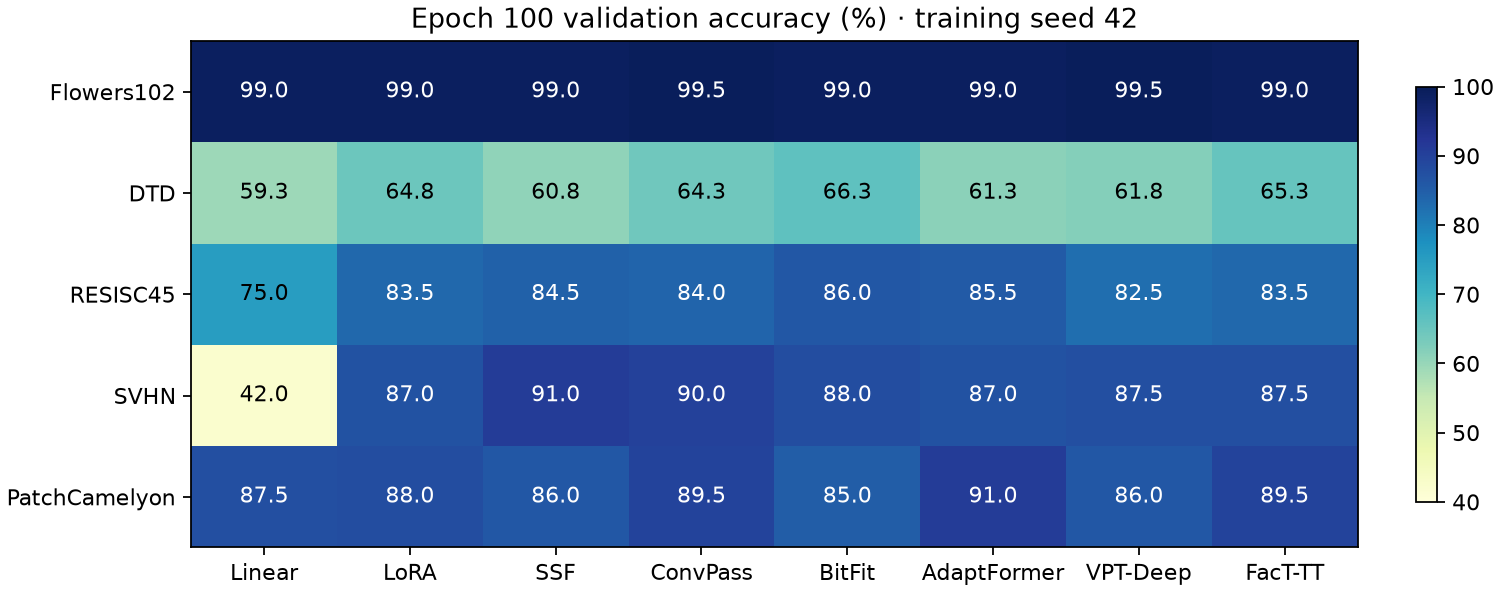

In [3]:
baseline = read_csv("baselines/metrics.csv")
assert len(baseline) == manifest["baseline_count"] == 40
display(Image(filename=str(FIGURES / "baseline_accuracy.png")))

Heatmap merangkum 40 kombinasi dataset dan metode pada development validation. Perbandingan NLL dan Brier dilakukan di dalam setiap dataset karena ruang kelas berbeda. Pemilihan pasangan berikutnya juga mempertimbangkan probabilitas, arah routing, dan budget fallback.

<a id="confidence-eda"></a>
### EDA confidence dan hasil fallback pada SVHN

Untuk diagnosis retrospektif pasangan terpilih, kami mengambil satu pembagian OOF dari **development validation SVHN**, dengan training seed 42 dan calibration split seed 42. Setiap gambar muncul sekali dalam 200 prediksi ConvPass. Confidence adalah probabilitas maksimum setelah temperature scaling yang dipasang tanpa fold gambar tersebut.

Grafik pertama mengelompokkan confidence ke empat kuartil dengan jumlah gambar sama. Grafik kedua memakai kuartil yang sama untuk menunjukkan perubahan akibat fallback ConvPass → SSF pada target 25%. Jumlah fallback aktual ditampilkan per kelompok. Kuartil dipakai untuk membaca pola. Ambang gate dihitung per fold sesuai protokol yang sudah tersimpan. [Keputusan routing per gambar](../results/checkpoint2/confirmation/routing_decisions.csv)

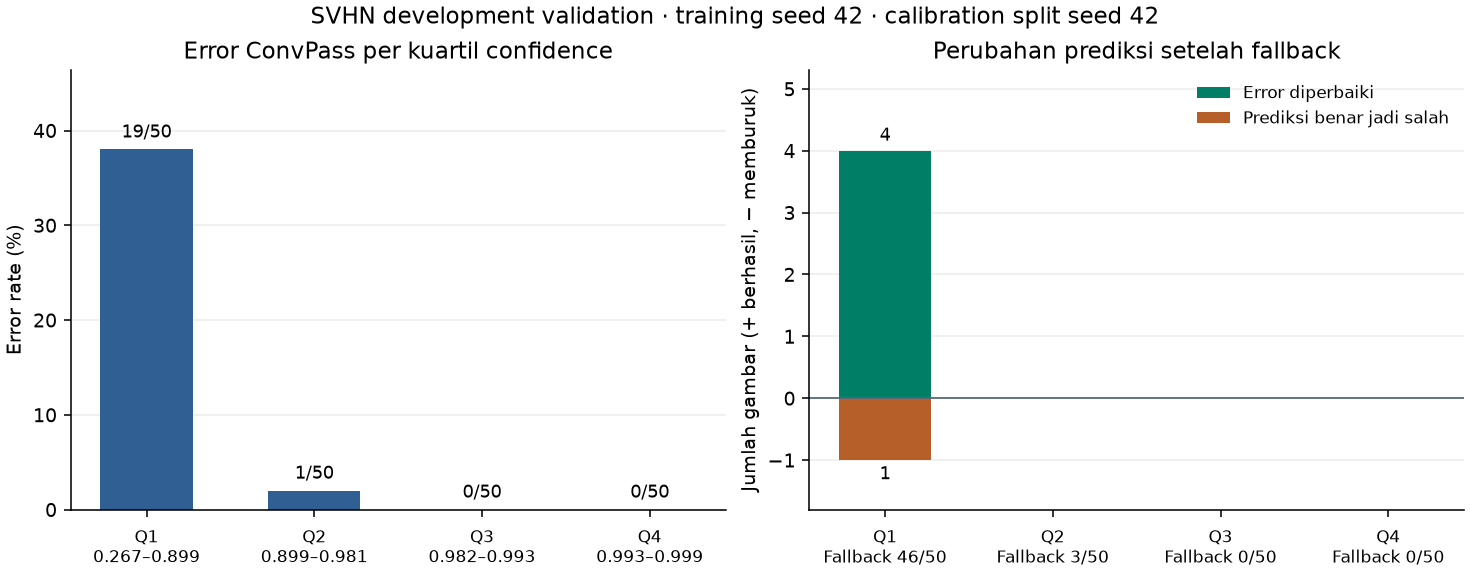

In [4]:
decisions = read_csv("confirmation/routing_decisions.csv")
svhn_eda = decisions.loc[
    decisions.dataset.eq("svhn")
    & decisions.evaluation_subset.eq("validation")
    & decisions.training_seed.eq(42)
    & decisions.split_seed.eq(42)
    & decisions.first_method.eq("convpass")
    & decisions.second_method.eq("ssf")
    & decisions.fallback_rule.eq("averaging")
    & decisions.target_fallback_rate.eq(.25)
].copy()
assert len(svhn_eda) == svhn_eda.sample_index.nunique() == 200

svhn_eda["quartile"] = pd.qcut(svhn_eda.first_confidence, q=4, labels=["Q1", "Q2", "Q3", "Q4"])
svhn_eda["primary_error"] = ~svhn_eda.first_correct
svhn_eda["fixed"] = svhn_eda.primary_error & svhn_eda.routed_correct
svhn_eda["reversed_correct"] = svhn_eda.first_correct & ~svhn_eda.routed_correct
assert not ((svhn_eda.fixed | svhn_eda.reversed_correct) & ~svhn_eda.fallback).any()

eda = svhn_eda.groupby("quartile", observed=True).agg(
    n=("sample_index", "size"), confidence_min=("first_confidence", "min"),
    confidence_max=("first_confidence", "max"), errors=("primary_error", "sum"),
    fallback=("fallback", "sum"), fixed=("fixed", "sum"), reversed=("reversed_correct", "sum"),
)
error_pct = 100 * eda.errors / eda.n
x = range(len(eda))
fig, (error_ax, fusion_ax) = plt.subplots(1, 2, figsize=(10.5, 4.1), layout="constrained")
fig.suptitle("SVHN development validation · training seed 42 · calibration split seed 42", fontsize=12)

errors = error_ax.bar(x, error_pct, width=.55, color="#306093")
error_ax.bar_label(errors, labels=[f"{e}/{n}" for e, n in zip(eda.errors, eda.n)], padding=4, fontsize=9)
error_ax.set(title="Error ConvPass per kuartil confidence", ylabel="Error rate (%)",
             ylim=(0, error_pct.max() * 1.22))
error_ax.set_xticks(x, [f"{q}\n{lo:.3f}–{hi:.3f}" for q, lo, hi in
                      zip(eda.index, eda.confidence_min, eda.confidence_max)])

fixed = fusion_ax.bar(x, eda.fixed, width=.55, color="#007e66", label="Error diperbaiki")
reversed_ = fusion_ax.bar(x, -eda.reversed, width=.55, color="#b65f29", label="Prediksi benar jadi salah")
fusion_ax.bar_label(fixed, labels=[str(n) if n else "" for n in eda.fixed], padding=3, fontsize=9)
fusion_ax.bar_label(reversed_, labels=[str(n) if n else "" for n in eda.reversed], padding=3, fontsize=9)
fusion_ax.set(title="Perubahan prediksi setelah fallback", ylabel="Jumlah gambar (+ berhasil, − memburuk)",
              ylim=(-1.8, 5.3))
fusion_ax.set_xticks(x, [f"{q}\nFallback {n}/{total}" for q, n, total in zip(eda.index, eda.fallback, eda.n)])
fusion_ax.axhline(0, color="#52657a", lw=.9)
fusion_ax.legend(loc="upper right", fontsize=8.5, frameon=False)

for ax in (error_ax, fusion_ax):
    ax.grid(axis="y", alpha=.23)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=8.5, pad=6)
with BytesIO() as rendered:
    fig.savefig(rendered, format="png", dpi=140)
    display(Image(data=rendered.getvalue()))
plt.close(fig)

Kuartil terbawah memuat **19 dari 20 error ConvPass** (38% dari 50 gambar), dan gate merutekan **46 dari 50** gambar di kuartil itu. Fusion memperbaiki empat error dan membalik satu prediksi benar. Tiga fallback lain terjadi di Q2 tanpa perubahan ketepatan. Q3 dan Q4 tidak menerima fallback, sehingga grafik kedua tidak memberi informasi tentang manfaat fusion jika kedua kelompok itu dipaksa memakai SSF.

**Implikasi.** Confidence rendah membantu menemukan kasus yang sulit bagi ConvPass pada pembagian ini. Untuk menilai manfaat aturan routing, bagian hasil membandingkan gate dengan matched random pada training seed lain dan pada test independen SVHN.

<a id="pair-screening"></a>
## II. Desain eksperimen dan pemilihan pasangan

### Calibration dan selective fusion

Temperature scaling membagi logits dengan scalar positif sebelum softmax. Temperature dipilih dengan minimisasi NLL. Urutan kelas dalam prediksi tetap sama. Confidence gate memakai probabilitas maksimum dari expert pertama.

```text
Gambar → expert pertama → probabilitas terkalibrasi
                              ├─ confidence ≥ ambang → gunakan prediksi pertama
                              └─ confidence < ambang → panggil expert kedua dan rata-ratakan probabilitas
```

| Pembanding | Pertanyaan yang dijawab |
| --- | --- |
| Calibrated singles | Apakah fusion memberi manfaat dibanding satu expert? |
| Always-on averaging | Berapa banyak manfaat dua expert yang dipertahankan? |
| Matched-budget random | Apakah confidence lebih baik dalam memilih gambar ketika jumlah fallback sama? |

**Accuracy** mengukur ketepatan kelas teratas. **NLL** menilai probabilitas pada kelas aktual melalui negative log probability. **Brier** mengukur squared error seluruh probabilitas kelas. Nilai lebih kecil lebih baik untuk NLL dan Brier. Pada fallback aktual sebesar r, selective memakai rata-rata **1 + r** pemanggilan model per gambar.

### Screening pada development validation

Eksperimen awal Linear → LoRA di DTD dan RESISC45 menyamakan budget random secara ekspektasi. Screening gabungan menambah SVHN dan PatchCamelyon dengan 12 pasangan berarah dari empat expert, target fallback 25%, 50%, dan 75%, serta dua aturan fusion. Replacement memakai prediksi expert kedua saat fallback. Averaging merata-ratakan kedua probabilitas. Random gabungan menyamakan jumlah fallback aktual per fold.

Seluruh screening memakai **training seed 42**. Lima fold out-of-fold memisahkan data fitting temperature dan threshold dari gambar yang dinilai. Pembagian diulang dengan **calibration split seed** 42, 43, dan 44. Ketiganya memakai gambar validation yang sama.

**Kontribusi tim.** Gipta membangun pipeline dan menguji pasangan antara Linear, LoRA, dan SSF. Charleen menguji pasangan yang melibatkan ConvPass dan menulis analisisnya. [Cross-check kedua kontributor](../results/checkpoint2/pilot/cross_checks.csv)

In [5]:
candidates = read_csv("pilot/selected_candidates.csv")
candidates["Dataset"] = candidates.dataset.map(NAMES)
candidates["Arah"] = candidates.first_method.map(NAMES) + " → " + candidates.second_method.map(NAMES)
candidates["Accuracy (%)"] = 100 * candidates.accuracy_mean
candidates["Fallback aktual (%)"] = 100 * candidates.fallback_fraction_mean
candidates["Target fallback (%)"] = 100 * candidates.target_fallback_rate
display(candidates[["Dataset", "Arah", "Target fallback (%)", "Fallback aktual (%)", "Accuracy (%)", "nll_mean",
               "always_on_nll", "matched_random_nll"]].rename(columns={
                   "nll_mean": "NLL selective", "always_on_nll": "NLL always-on",
                   "matched_random_nll": "NLL random"}).round(4).reset_index(drop=True))

averaging = read_csv("pilot/averaging_comparison.csv").set_index("contributor")
scale = read_csv("pilot/calibration_summary.csv").pivot(
    index=["dataset", "method"], columns="stage", values=["nll_mean", "brier_mean"])
def improved(metric):
    return int((scale[metric].temperature_scaled_oof < scale[metric].raw_oof).sum())
display(Markdown(
    f"Temperature scaling menurunkan NLL pada **{improved('nll_mean')}/{len(scale)}** kombinasi "
    f"dan Brier pada **{improved('brier_mean')}/{len(scale)}**. "
    f"Averaging menghasilkan NLL lebih rendah daripada replacement pada "
    f"**{averaging.loc['team', 'averaging_lower_nll']}/{averaging.loc['team', 'matched_configurations']}** "
    f"perbandingan gabungan. Bagian Charleen mencakup "
    f"**{averaging.loc['charleen', 'averaging_lower_nll']}/{averaging.loc['charleen', 'matched_configurations']}**."
))

,Dataset,Arah,Target fallback (%),Fallback aktual (%),Accuracy (%),NLL selective,NLL always-on,NLL random
0,PatchCamelyon,ConvPass → Linear,25.0,25.8333,90.0000,0.2293,0.2549,0.2573
1,SVHN,ConvPass → SSF,25.0,25.3333,91.5000,0.2964,0.3086,0.3200
2,RESISC45,ConvPass → SSF,75.0,74.1667,86.5000,0.5161,0.5206,0.5307
3,DTD,LoRA → SSF,75.0,74.8744,64.9916,1.2423,1.2414,1.2681


Temperature scaling menurunkan NLL pada **16/16** kombinasi dan Brier pada **13/16**. Averaging menghasilkan NLL lebih rendah daripada replacement pada **110/144** perbandingan gabungan. Bagian Charleen mencakup **56/72**.

Tabel memilih mean NLL terendah per dataset dari kombinasi yang diuji pada development validation. Dua konfigurasi yang dibawa ke evaluasi tiga seed adalah **SVHN ConvPass → SSF** dan **PatchCamelyon ConvPass → Linear**, keduanya memakai averaging dan target fallback 25%. Karena gambar validation juga dipakai dalam pemilihan, evaluasi tiga seed di split tersebut mengukur variasi training. Test SVHN menjadi evaluasi terpisah terhadap konfigurasi terkunci.

<a id="training-seeds"></a>
## III. Evaluasi

### Development validation lintas training seed

Resep dan pasangan tetap pada training seed 42, 43, dan 44. Setiap skor seed adalah mean dari tiga pembagian calibration. Matched random memakai 20 pengulangan per pembagian. SD antar-training seed dilaporkan terpisah dari variasi pembagian calibration.

[Skor per seed](../results/checkpoint2/confirmation/metrics_by_training_seed.csv) · [Ringkasan tiga seed](../results/checkpoint2/confirmation/summary_three_training_seeds.csv) · [Daftar run](../results/checkpoint2/confirmation/availability.csv)

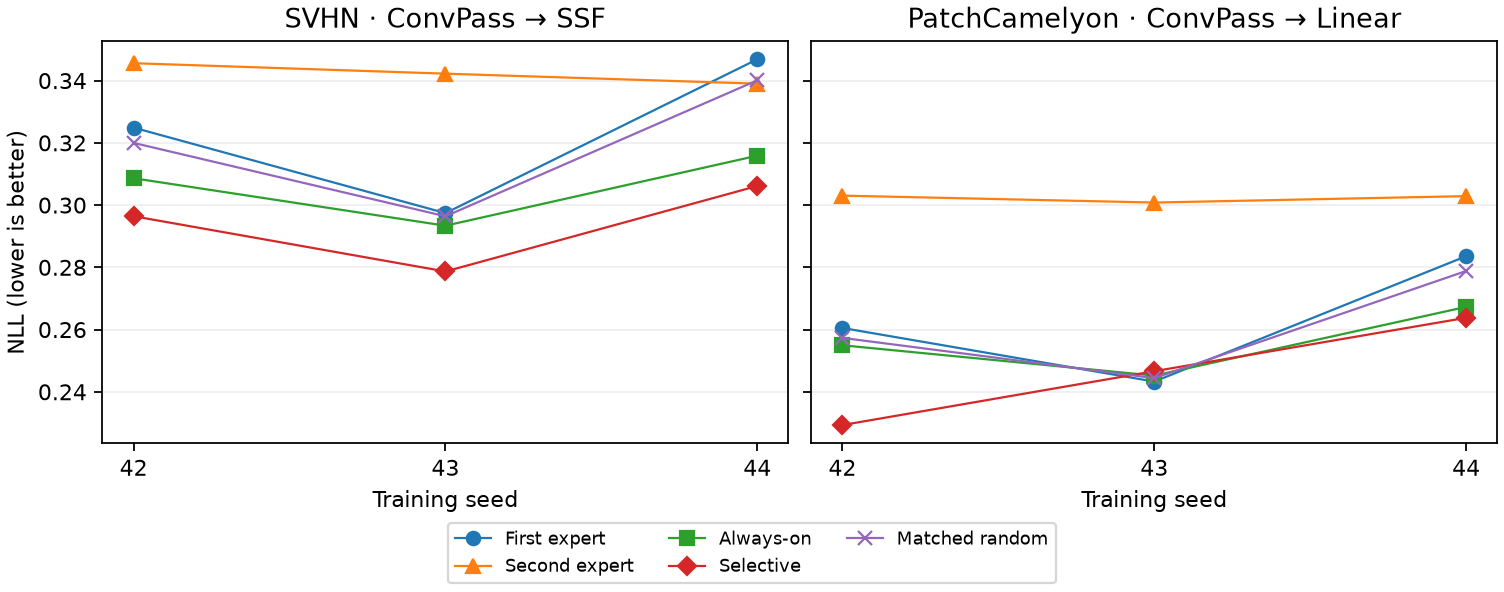

Di development validation, selective menyamai accuracy always-on pada **6/6** kombinasi dataset–seed dan menurunkan NLL pada **5/6** kombinasi.

In [6]:
availability = read_csv("confirmation/availability.csv")
scores = read_csv("confirmation/metrics_by_training_seed.csv")
assert len(availability) == manifest["confirmation_pairs_target"] == 6
assert availability.status.eq("evaluated").sum() == manifest["confirmation_pairs_evaluated"] == 6
assert len(scores) == 5 * manifest["confirmation_pairs_evaluated"]

labels = {
    "calibrated_first": "Expert pertama", "calibrated_second": "Expert kedua",
    "always_on_averaging": "Always-on", "confidence_routing": "Selective",
    "random_routing": "Matched random",
}
comparison = scores.pivot(index=["dataset", "training_seed"], columns="strategy",
                          values=["accuracy_mean", "nll_mean"])
always_on = "always_on_averaging"
selective = "confidence_routing"
accuracy_ties = comparison["accuracy_mean"][selective].sub(comparison["accuracy_mean"][always_on]).abs().lt(1e-12)
lower_nll = comparison["nll_mean"][selective].lt(comparison["nll_mean"][always_on])
display(Image(filename=str(FIGURES / "nll_by_training_seed.png")))
display(Markdown(
    f"Di development validation, selective menyamai accuracy always-on pada "
    f"**{accuracy_ties.sum()}/{len(accuracy_ties)}** kombinasi dataset–seed "
    f"dan menurunkan NLL pada **{lower_nll.sum()}/{len(lower_nll)}** kombinasi."
))

<a id="svhn-test"></a>
### Test independen SVHN

Untuk ConvPass → SSF, kedua temperature dan threshold pada target fallback 25% dikunci per training seed menggunakan 200 gambar validation. Keenam checkpoint kemudian memproses 26.032 gambar test dari 10 kelas. Setiap random draw memakai jumlah fallback aktual dari gate pada test untuk seed yang sama.

Tabel berisi mean lintas training seed dan sample SD untuk accuracy. Grafik menampilkan trade-off dua metrik terhadap jumlah panggilan model. [Skor test per seed](../results/checkpoint2/holdout/svhn-test-per-seed.csv) · [Protokol terkunci](../results/checkpoint2/holdout/holdout-policy.json)

,Accuracy (%),SD (pp),NLL,Brier,Calls/gambar
strategy,,,,,
ConvPass,90.4515,0.3922,0.3192,0.1416,1.0000
SSF,90.2236,0.5204,0.3223,0.1456,1.0000
Always-on,91.6833,0.4800,0.2869,0.1273,2.0000
Selective,91.6782,0.4860,0.2885,0.1270,1.2562
Matched random,90.7660,0.4190,0.3109,0.1379,1.2562


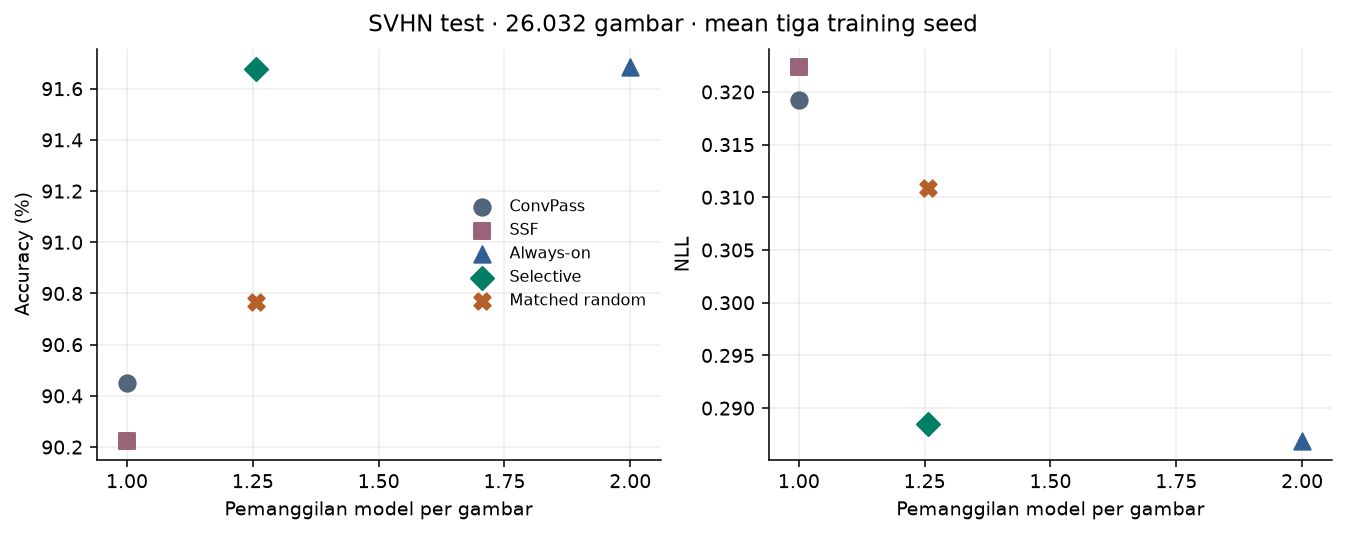

In [7]:
test_scores = pd.read_csv(holdout / "svhn-test-per-seed.csv")
test_labels = dict(labels, calibrated_first="ConvPass", calibrated_second="SSF")
test_labels["matched_random"] = test_labels.pop("random_routing")
assert set(test_scores.training_seed) == set(test_manifest["training_seeds"])
assert test_scores.n.eq(test_manifest["sample_count"]).all()
assert set(test_scores.strategy) == set(test_labels)
assert not test_scores.duplicated(["training_seed", "strategy"]).any()
assert len(test_scores) == len(test_labels) * len(test_manifest["training_seeds"])
test_scores["Accuracy (%)"] = 100 * test_scores.accuracy
test_summary = test_scores.groupby("strategy").agg(
    Accuracy=("Accuracy (%)", "mean"), SD=("Accuracy (%)", "std"),
    NLL=("nll", "mean"), Brier=("brier", "mean"), Calls=("calls", "mean"),
)

test_summary = test_summary.reindex(test_labels).rename(index=test_labels)
display(test_summary.rename(columns={"Accuracy": "Accuracy (%)", "SD": "SD (pp)", "Calls": "Calls/gambar"}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), layout="constrained")
styles = {
    "ConvPass": ("#52657a", "o"), "SSF": ("#9a6379", "s"),
    "Always-on": ("#306093", "^"), "Selective": ("#007e66", "D"),
    "Matched random": ("#b65f29", "X"),
}
for strategy, row in test_summary.iterrows():
    color, marker = styles[strategy]
    for ax, metric in zip(axes, ("Accuracy", "NLL")):
        ax.scatter(row.Calls, row[metric], color=color, marker=marker, s=71, label=strategy, zorder=3)
for ax, metric in zip(axes, ("Accuracy (%)", "NLL")):
    ax.set(xlabel="Pemanggilan model per gambar", ylabel=metric, xlim=(0.94, 2.06))
    ax.set_xticks([1.0, 1.25, 1.5, 1.75, 2.0])
    ax.grid(alpha=.22)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(loc="center right", fontsize=8, frameon=False)
fig.suptitle("SVHN test · 26.032 gambar · mean tiga training seed", fontsize=12)
with BytesIO() as rendered:
    fig.savefig(rendered, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=rendered.getvalue()))
plt.close(fig)

Selective dan always-on sama-sama membulat ke **91,68% accuracy**, dengan selisih paling besar tiga prediksi benar per seed. Selective memakai **1,256 vs 2,000 pemanggilan model per gambar** dan menghasilkan NLL **0,2885 vs 0,2869**. Pada budget yang sama, selective mengungguli matched random pada accuracy, NLL, dan Brier di ketiga seed.

<a id="discussion"></a>
## IV. Diagnosis dan kesimpulan

### Kapan fallback merugikan?

Pada PatchCamelyon training seed 43, ConvPass mencapai 91,0% accuracy dan selective mencapai 89,5% pada 200 gambar development validation. Perbandingan per gambar membedakan **kesalahan yang masuk fallback**, **kesalahan yang diperbaiki**, dan **prediksi benar yang berubah menjadi salah**. [Keputusan routing per gambar](../results/checkpoint2/confirmation/routing_decisions.csv)

In [8]:
failure = decisions.loc[decisions.dataset.eq("patch_camelyon") & decisions.training_seed.eq(43)].copy()
assert failure.groupby("split_seed").sample_index.nunique().to_dict() == {42: 200, 43: 200, 44: 200}
primary_error = ~failure.first_correct
fixed = primary_error & failure.routed_correct
reversed_correct = failure.first_correct & ~failure.routed_correct
assert not ((fixed | reversed_correct) & ~failure.fallback).any()
failure_summary = failure.assign(
    primary_error=primary_error, routed_error=primary_error & failure.fallback,
    fixed=fixed, reversed_correct=reversed_correct,
).groupby("split_seed").agg(
    Fallback=("fallback", "sum"), primary_errors=("primary_error", "sum"),
    routed_errors=("routed_error", "sum"), fixed=("fixed", "sum"),
    reversed_correct=("reversed_correct", "sum"),
)
display(failure_summary.rename_axis("Calibration split seed").rename(columns={
    "primary_errors": "Error ConvPass", "routed_errors": "Error masuk fallback",
    "fixed": "Error diperbaiki", "reversed_correct": "Jawaban benar jadi salah",
}))

,Fallback,Error ConvPass,Error masuk fallback,Error diperbaiki,Jawaban benar jadi salah
Calibration split seed,,,,,
42,53,18,12,4,7
43,54,18,13,4,7
44,52,18,12,4,7


Pada setiap pembagian calibration, fusion memperbaiki empat prediksi dan mengubah tujuh prediksi benar menjadi salah. Untuk meningkatkan accuracy, jumlah kesalahan yang diperbaiki perlu melebihi jumlah prediksi benar yang berubah menjadi salah.

### Label noise pada SVHN

Pada training seed 42, corruption seed 2026 memilih **160 dari 800 label training** untuk diganti seragam ke salah satu dari sembilan kelas lain. ConvPass dan SSF menerima daftar perubahan yang sama. Gambar dan 200 label development validation tetap sama. Kondisi clean dan noisy memakai resep yang sama, dengan hardware dan versi runner berbeda.

Untuk tiap kondisi, temperature dan threshold ditentukan dengan protokol lima fold OOF yang sama. Target fallback adalah 25%. Random memakai 20 pengulangan dengan jumlah fallback per fold yang sama.

In [9]:
pairwise_dir = ROOT / "results/label_noise/svhn/pairwise"
pairwise_status = json.loads((pairwise_dir / "status.json").read_text())
assert not pairwise_status["final_test_used"]
assert pairwise_status["validation_n"] == 200 and pairwise_status["training_noise_percent"] == [0, 20]

strategies = {
    "calibrated_first": "ConvPass",
    "calibrated_second": "SSF",
    "always_on_averaging": "Always-on averaging",
    "confidence_routing": "Selective fusion",
    "random_routing": "Matched random",
}
noise_scores = pd.read_csv(pairwise_dir / "strategy_summary.csv")
noise_scores["Strategy"] = pd.Categorical(noise_scores.pop("strategy").map(strategies), list(strategies.values()))
noise_scores["Accuracy (%)"] = 100 * noise_scores.pop("accuracy")
noise_scores["Fallback (%)"] = 100 * noise_scores.pop("fallback_fraction")
noise_scores = noise_scores.rename(columns={
    "training_noise_percent": "Label noise (%)", "nll": "NLL", "brier": "Brier",
    "forward_passes_per_image": "Forward pass per gambar",
})
display(noise_scores.sort_values(["Label noise (%)", "Strategy"])[[
    "Label noise (%)", "Strategy", "Accuracy (%)", "NLL", "Brier", "Fallback (%)", "Forward pass per gambar",
]].reset_index(drop=True).round(4))

,Label noise (%),Strategy,Accuracy (%),NLL,Brier,Fallback (%),Forward pass per gambar
0,0,ConvPass,90.0000,0.3249,0.1391,0.0000,1.0000
1,0,SSF,91.0000,0.3456,0.1474,0.0000,1.0000
2,0,Always-on averaging,91.5000,0.3086,0.1279,100.0000,2.0000
3,0,Selective fusion,91.5000,0.2964,0.1234,25.3333,1.2533
4,0,Matched random,90.4667,0.3200,0.1357,25.3333,1.2533
5,20,ConvPass,83.0000,0.5610,0.2421,0.0000,1.0000
6,20,SSF,77.5000,0.7168,0.3054,0.0000,1.0000
7,20,Always-on averaging,83.0000,0.5590,0.2415,100.0000,2.0000
8,20,Selective fusion,82.8333,0.5637,0.2392,25.6667,1.2567
9,20,Matched random,83.0333,0.5593,0.2418,25.6667,1.2567


Dengan 20% label noise, selective mencapai **82,83%** dan ConvPass **83,00%**. Brier turun dari 0,2421 ke 0,2392, sementara NLL naik dari 0,5610 ke 0,5637. Pada kondisi noisy, gate memperbaiki tiga kesalahan dan merusak tiga hingga empat prediksi benar per pembagian calibration. [Diagnosis gate](../results/label_noise/svhn/pairwise/gate_diagnostics.csv)

### Kesimpulan dan lingkup hasil

- **SVHN test, training clean.** Confidence routing mengungguli random pada budget yang sama dan mendekati accuracy always-on dengan 37,2% lebih sedikit pemanggilan model. NLL selective sedikit lebih tinggi daripada always-on.
- **Development validation.** PatchCamelyon seed 43 menunjukkan bahwa fallback dapat menambah error. Eksperimen SVHN dengan label noise memakai satu training seed, satu corruption mask, dan dua expert. LoRA noisy belum menghasilkan artefak evaluasi lengkap.
- **Biaya inferensi.** Jumlah pemanggilan model dihitung dari kebijakan routing atas logits tersimpan. Pengukuran latency memerlukan profiling eksekusi aktual.

<a id="reproduction"></a>
## Reproduksi dan artefak

| Bukti | Sumber |
| --- | --- |
| Development | [Manifest](../results/checkpoint2/manifest.json), [rekap screening](../results/checkpoint2/pilot/routing_summary.csv), [sumber Gipta](../results/checkpoint2/pilot/source/gipta/original_manifest.json), [sumber Charleen](../results/checkpoint2/pilot/source/charleen/original_manifest.json) |
| Calibration dan routing | [Temperature per fold](../results/checkpoint2/confirmation/temperatures.csv), [threshold](../results/checkpoint2/confirmation/routing_thresholds.csv), [metrik per pembagian](../results/checkpoint2/confirmation/metrics_by_split.csv) |
| SVHN test | [Manifest](../results/checkpoint2/holdout/manifest.json), [protokol](../results/checkpoint2/holdout/holdout-policy.json), [audit split](../results/checkpoint2/holdout/test-split-integrity.jsonl), [skor per seed](../results/checkpoint2/holdout/svhn-test-per-seed.csv) |
| Label noise | [Manifest korupsi](../results/label_noise/svhn/runs/corruption.json), [cakupan eksperimen](../results/label_noise/svhn/analysis/status.json), [tabel dua expert](../results/label_noise/svhn/pairwise/strategy_summary.csv), [diagnosis](../results/label_noise/svhn/pairwise/gate_diagnostics.csv) |

Untuk **Run All** di CPU, gunakan environment dari [requirements-analysis.txt](../requirements-analysis.txt) dan buka dari root repo atau folder `notebooks/`. Notebook membaca hasil tersimpan. [Panduan artefak](../docs/CHECKPOINT2_ARTIFACTS.md) menjelaskan reproduksi development dan label noise.

[Mai et al., CVPR 2025](https://arxiv.org/html/2409.16434v5) · [Kode upstream yang dipin](https://github.com/OSU-MLB/ViT_PEFT_Vision/tree/cea7e21b2ddecef8172f5d177da5a29d531c4279)